# Bitcoin OTC: comparison with theory

This notebook compares our results with the formulas from the course. It reads the results of `scripts/theory_comparison.py`, plus two checks from `temporal_sensitivity.py` and `community_profiles.py` (run `python scripts/reproduce.py` first). Small calculations are redone by hand so we can explain them.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from scipy import special
from IPython.display import display, Image

ROOT = Path('..')  # project folder
THEORY = ROOT / 'outputs' / 'theory'
SENS = ROOT / 'outputs' / 'sensitivity'

meta = json.loads((THEORY / 'metadata.json').read_text())
expectations = pd.read_csv(THEORY / 'model_expectations.csv')
tails = pd.read_csv(THEORY / 'degree_tail_fits.csv')
benchmarks = pd.read_csv(THEORY / 'attachment_benchmarks.csv')
returns = pd.read_csv(THEORY / 'reciprocation_by_prior_degree.csv')
thresholds = pd.read_csv(THEORY / 'percolation_thresholds.csv')
centrality = pd.read_csv(THEORY / 'centrality_comparison.csv')
equal_volume = pd.read_csv(SENS / 'annual_equal_volume_check.csv')
stability = pd.read_csv(SENS / 'community_stability.csv')

## 1. Centrality

- **In-degree**: positive ratings received. **Out-degree**: positive ratings given.
- **Betweenness**: the share of shortest paths (along positive arrows) that pass through a user.

The structure script estimated betweenness from 64 sample users, which is quick but rough, so here we compare it with the exact value.

In [2]:
display(centrality.head(10).round(4))
pd.Series(meta['centrality']).round(3)

,betweenness_rank,node,positive_in_degree,positive_out_degree,betweenness_approx,betweenness_exact,in_degree_rank
0,1,35,535,753,0.1483,0.1425,1
1,2,2642,411,397,0.0725,0.0616,2
2,3,1,226,206,0.0462,0.0440,5
3,4,7,216,225,0.0628,0.0400,7
4,5,905,226,223,0.0389,0.0394,5
5,6,4172,211,190,0.0374,0.0355,8
6,7,1810,270,244,0.0235,0.0354,3
7,8,2028,234,267,0.0378,0.0336,4
8,9,13,190,193,0.0366,0.0300,10
9,10,1953,153,152,0.0478,0.0298,15


spearman_sampled_vs_exact_betweenness       0.951
spearman_in_degree_vs_out_degree            0.837
spearman_in_degree_vs_exact_betweenness     0.868
top_10_overlap_sampled_vs_exact             9.000
top_20_overlap_sampled_vs_exact            13.000
top_10_overlap_in_degree_vs_exact           9.000
dtype: float64

In-degree and out-degree go together (Spearman 0.84), because most ratings are returned. Betweenness mostly follows in-degree (Spearman 0.87), so the hubs are also the main bridges. The 64-sample estimate gets the overall order right (0.95) but individual values are noisy, so we use the exact ones. Betweenness describes position in this graph; it does not mean money or trust flowed through that user.

## 2. Formulas from the course

The simulated ER and BA graphs (notebook 02) should agree with the course formulas. Here we work the formulas out by hand from $N$ and $L$:

- ER: $\sigma_k = \sqrt{\langle k\rangle}$, giant component $S = 1 - e^{-\langle k\rangle S}$, $\langle d\rangle \approx \ln N / \ln\langle k\rangle$, $\langle C\rangle = p$
- BA: $k_{max} \approx m\sqrt{N}$, $\langle d\rangle \approx \ln N / \ln\ln N$, $\langle C\rangle \sim (\ln N)^2 / N$

In [3]:
N, L = 5881, 18591
k_mean = 2 * L / N
p = 2 * L / (N * (N - 1))
m = 3  # BA links per new node (closest whole number to L/N)

# S = 1 - exp(-<k> S) has no closed form, so we repeat it until the value settles
S = 0.5
for step in range(100):
    S = 1 - np.exp(-k_mean * S)

print('ER  <k> =', round(k_mean, 3), '  p =', round(p, 6))
print('ER  degree std sqrt(<k>) =', round(np.sqrt(k_mean), 3))
print('ER  giant component S =', round(S, 4))
print('ER  mean distance ln N / ln <k> =', round(np.log(N) / np.log(k_mean), 3))
print('ER  clustering p =', round(p, 4))
print('BA  largest hub m sqrt(N) =', round(m * np.sqrt(N), 1))
print('BA  mean distance ln N / ln ln N =', round(np.log(N) / np.log(np.log(N)), 3))
print('BA  clustering (ln N)^2 / N =', round(np.log(N) ** 2 / N, 4))

expectations.drop(columns=['formula']).round(4)

ER  <k> = 6.322   p = 0.001075
ER  degree std sqrt(<k>) = 2.514
ER  giant component S = 0.9982
ER  mean distance ln N / ln <k> = 4.707
ER  clustering p = 0.0011
BA  largest hub m sqrt(N) = 230.1
BA  mean distance ln N / ln ln N = 4.016
BA  clustering (ln N)^2 / N = 0.0128


,quantity,observed,er_formula,er_simulated_mean,er_simulated_std,ba_formula,ba_simulated_mean,ba_simulated_std,rewired_mean,rewired_std,internal_link_formula,internal_link_simulated_mean,internal_link_simulated_std
0,Mean degree,6.3224,6.3224,6.3224,0.0000,6.0000,5.9969,0.0000,6.3224,0.0000,NaN,6.6823,0.0296
1,Degree standard deviation,20.3638,2.5144,2.4934,0.0238,NaN,8.2756,0.2717,20.3638,0.0000,NaN,23.0772,0.2506
2,Maximum degree,788.0000,17.0000,17.1000,1.1972,230.0630,231.0000,24.2716,788.0000,0.0000,NaN,332.9000,18.5918
3,Heterogeneity <k^2>/<k>,71.9120,7.3224,7.3058,0.0188,NaN,17.4281,0.7475,71.9120,0.0000,NaN,86.3860,1.6442
4,Largest component share,0.9439,0.9982,0.9982,0.0006,1.0000,1.0000,0.0000,0.9272,0.0020,NaN,1.0000,0.0000
5,Mean path length (largest component),3.7610,4.7066,4.9132,0.0539,4.0165,4.0821,0.0702,3.5190,0.0847,NaN,3.4825,0.0593
6,Average local clustering,0.1550,0.0011,0.0010,0.0002,0.0128,0.0081,0.0011,0.0615,0.0019,NaN,0.0974,0.0027
7,Transitivity,0.0570,0.0011,0.0011,0.0002,NaN,0.0042,0.0003,0.0430,0.0011,NaN,0.1164,0.0040
8,Degree assortativity,-0.1449,0.0000,0.0010,0.0067,NaN,-0.0444,0.0053,-0.1144,0.0019,NaN,-0.1421,0.0097
9,Louvain modularity,0.5042,NaN,0.3688,0.0016,NaN,0.3879,0.0019,0.3338,0.0010,NaN,0.3237,0.0014


The ER and BA simulations land close to their formulas, so the simulations behave as theory says. The real network is far from both: its biggest hub (788) is much bigger than either model's, and its clustering is far above ER's. Its mean distance is shorter than ER's while its clustering is much higher, which is the **small-world** property.

In [4]:
print('Exact mean path (largest component):', round(meta['exact_mean_path_largest_component'], 3))
print('Earlier estimate from 32 sample users:', round(meta['sampled_mean_path_stored'], 3))
print('Clustering, real / ER:', round(meta['small_world']['clustering_ratio_to_er'], 1))
print('Mean path, real / ER:', round(meta['small_world']['path_ratio_to_er'], 3))

Exact mean path (largest component): 3.761
Earlier estimate from 32 sample users: 3.559
Clustering, real / ER: 153.8
Mean path, real / ER: 0.765


## 3. Is the degree distribution a power law?

A straight line on a log–log plot is not enough (Chapter 4). Above a cutoff $k_{min}$, a power law gives

$$P(k) = \frac{k^{-\gamma}}{\zeta(\gamma, k_{min})},$$

where $\zeta$ makes the probabilities add up to one. The best $\gamma$ is the one that makes the observed degrees most likely. The **invented** example below tries many values of $\gamma$ and keeps the best one.

In [5]:
degrees = np.array([3, 3, 3, 3, 4, 4, 4, 5, 5, 6, 7, 8, 10, 14, 25])
k_min = 3

gammas = np.arange(1.5, 5.0, 0.01)
log_likelihood = []
for g in gammas:
    log_likelihood.append(-len(degrees) * np.log(special.zeta(g, k_min)) - g * np.log(degrees).sum())

best_gamma = gammas[np.argmax(log_likelihood)]
print('Best gamma for the invented degrees:', round(best_gamma, 2))

Best gamma for the invented degrees: 2.29


For the real network the script also chooses $k_{min}$, estimates the uncertainty by resampling, tests whether the data could come from the fitted power law, and compares it with other tail shapes: lognormal, exponential, and a power law with a cutoff.

,measure,k_min,gamma,gamma_ci_low,gamma_ci_high,goodness_of_fit_p,p_vs_lognormal,p_vs_truncated,expected_max_degree,observed_max_degree
0,Undirected degree,7.0,2.090,1.912,2.238,0.002,0.004,0.0,4290.017,788.0
1,Positive in-degree,9.0,2.154,1.864,2.278,0.000,0.008,0.0,2718.004,535.0
2,Positive out-degree,7.0,2.092,1.932,2.779,0.000,0.004,0.0,3727.230,753.0
3,BA reference,5.0,2.744,2.650,2.791,NaN,NaN,NaN,NaN,NaN
4,Internal-link reference,2.5,1.875,1.791,1.913,NaN,NaN,NaN,NaN,NaN


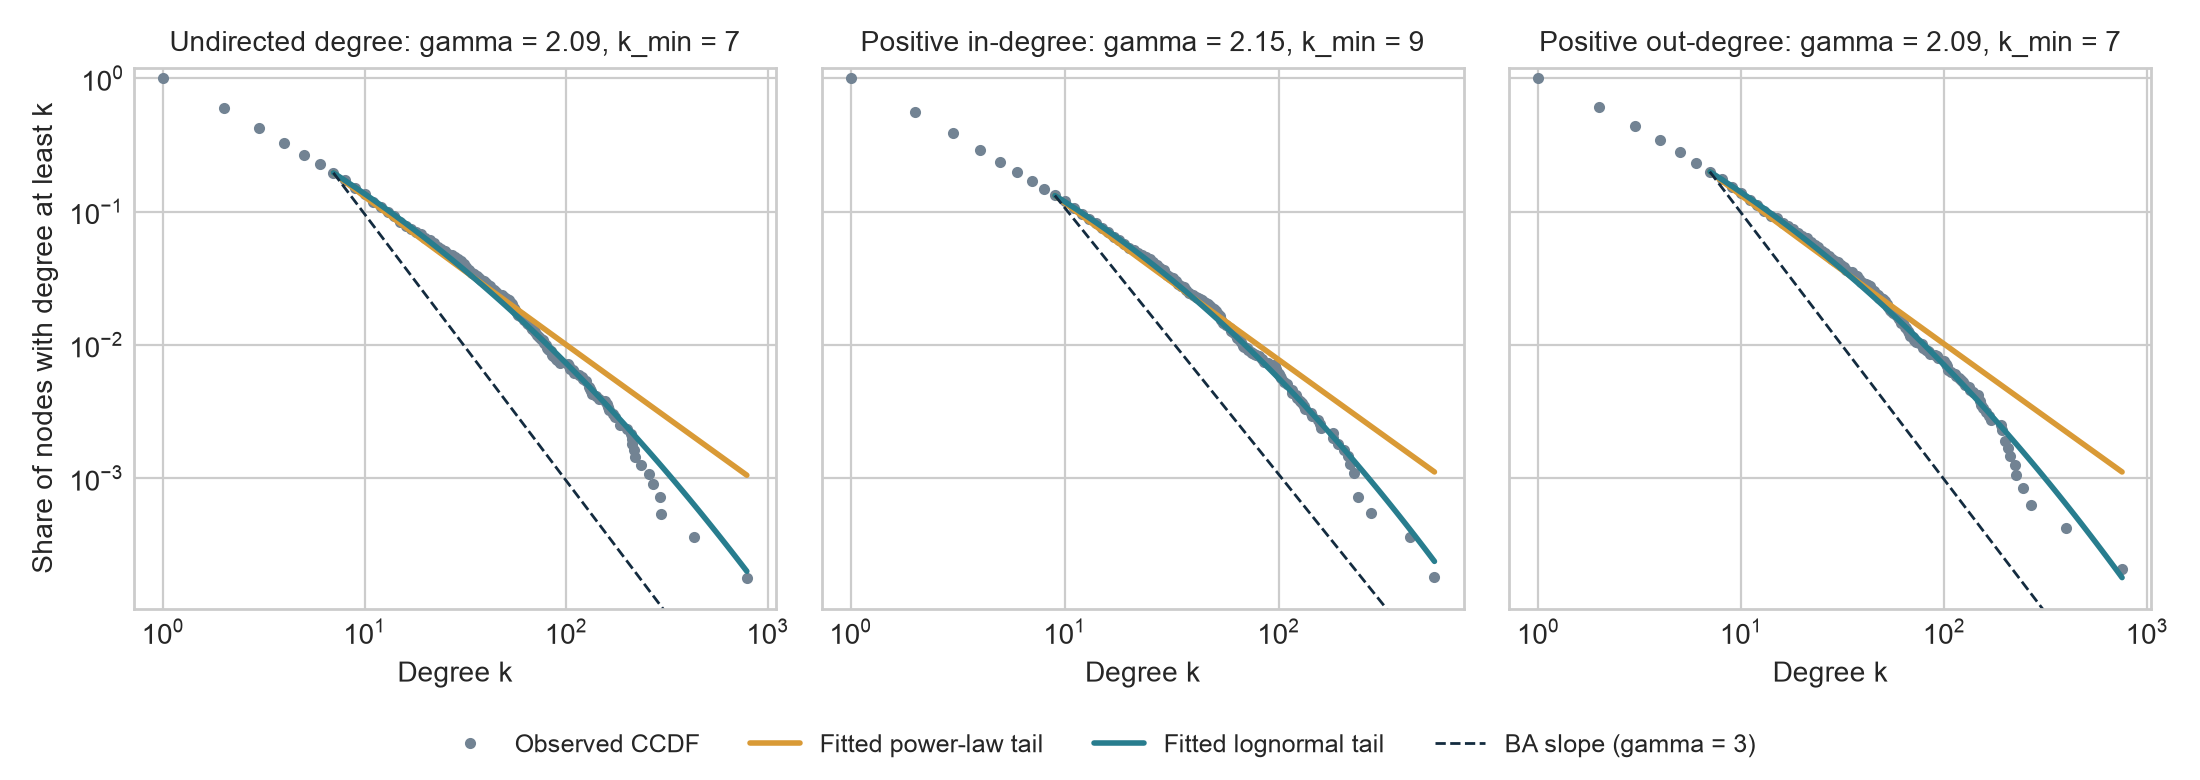

In [6]:
columns = ['measure', 'k_min', 'gamma', 'gamma_ci_low', 'gamma_ci_high', 'goodness_of_fit_p',
           'p_vs_lognormal', 'p_vs_truncated', 'expected_max_degree', 'observed_max_degree']
display(tails[columns].round(3))
Image(filename=str(THEORY / 'degree_ccdf_fits.png'))

All three exponents are near 2.1, so the tail is heavier than BA's $\gamma = 3$. But the pure power law is rejected (goodness-of-fit $p \le 0.002$), and a lognormal or a power law with a cutoff fits better. Above about $k = 100$ the data bend below the straight line. So the network is **heavy-tailed and hub-dominated, but not strictly scale-free**.

## 4. Why BA's growth rule does not fit

BA adds every link together with a new node. We checked this by looking at each link when it first appeared.

In [7]:
pd.Series(meta['growth']).round(4)

users_in_positive_ratings                5573.0000
undirected_links                        18591.0000
links_arriving_with_a_new_user           5491.0000
links_between_existing_users            13100.0000
share_between_existing_users                0.7046
links_per_new_user_m                        0.9853
internal_links_per_new_user_n               2.3506
gamma_double_preferential_attachment        2.1733
dtype: float64

Most links (70.5%) join two users who were already there, which BA does not allow. Barabási's book (Section 6.5, *Internal links*) extends BA: each step adds a new node with $m$ links plus $n$ links between existing nodes, with both ends chosen in proportion to degree (double preferential attachment). Then (Eq. 6.27)

$$\gamma = 2 + \frac{m}{m + 2n}.$$

With $n = 0$ this gives BA's $\gamma = 3$.

In [8]:
def internal_link_gamma(m, n):
    return 2 + m / (m + 2 * n)

growth = meta['growth']
m_measured = growth['links_per_new_user_m']
n_measured = growth['internal_links_per_new_user_n']
print('Check with n = 0 (plain BA):', internal_link_gamma(3, 0))
print('Measured m =', round(m_measured, 2), '  n =', round(n_measured, 2))
print('Predicted gamma:', round(internal_link_gamma(m_measured, n_measured), 3))

fits = tails.set_index('measure')
print('Fitted gamma:', round(fits.loc['Undirected degree', 'gamma'], 3),
      ' interval', round(fits.loc['Undirected degree', 'gamma_ci_low'], 2),
      'to', round(fits.loc['Undirected degree', 'gamma_ci_high'], 2))
print('Same fit on simulated internal-link graphs:', round(fits.loc['Internal-link reference', 'gamma'], 3))

Check with n = 0 (plain BA): 3.0
Measured m = 0.99   n = 2.35
Predicted gamma: 2.173
Fitted gamma: 2.09  interval 1.91 to 2.24
Same fit on simulated internal-link graphs: 1.875


The predicted 2.17 is inside the fitted interval and BA's 3 is not. The fitting method gives somewhat low values on finite graphs (2.74 on BA graphs, whose true value is 3, and 1.88 on simulated internal-link graphs); on that scale our 2.09 lies between the two, closer to the extension. So internal links help explain the tail, but not completely: the extension still makes the biggest hub too small and the communities too weak (table in Section 2).

## 5. Preferential attachment with different comparisons

Notebooks 03 and 04 compared recipients with all possible recipients and with similar ones. Here we also fit the course's **nonlinear preferential attachment** rule $\Pi(k) \propto (k+1)^{\alpha}$ for each comparison (the $+1$ lets users with no ratings be chosen). $\alpha = 1$ is BA's linear rule; $\alpha < 1$ is sublinear.

,benchmark,events,attachment_exponent_alpha,alpha_standard_error,ratio_0,ratio_2-3,ratio_32+
0,Uniform,27133,1.069,0.005,1.759,0.484,12.697
1,Tenure and activity,26993,0.685,0.009,3.847,0.773,1.649
2,Tenure only,27133,1.388,0.005,1.246,0.491,18.455
3,Activity only,27105,0.363,0.006,3.939,0.773,1.706
4,Tenure and ratings given,26588,0.611,0.009,2.751,0.847,1.440
5,"Uniform, first rating in a pair",13695,1.001,0.007,0.715,0.553,11.088
6,"Tenure and activity, first rating in a pair",13617,0.745,0.013,1.158,0.859,1.631


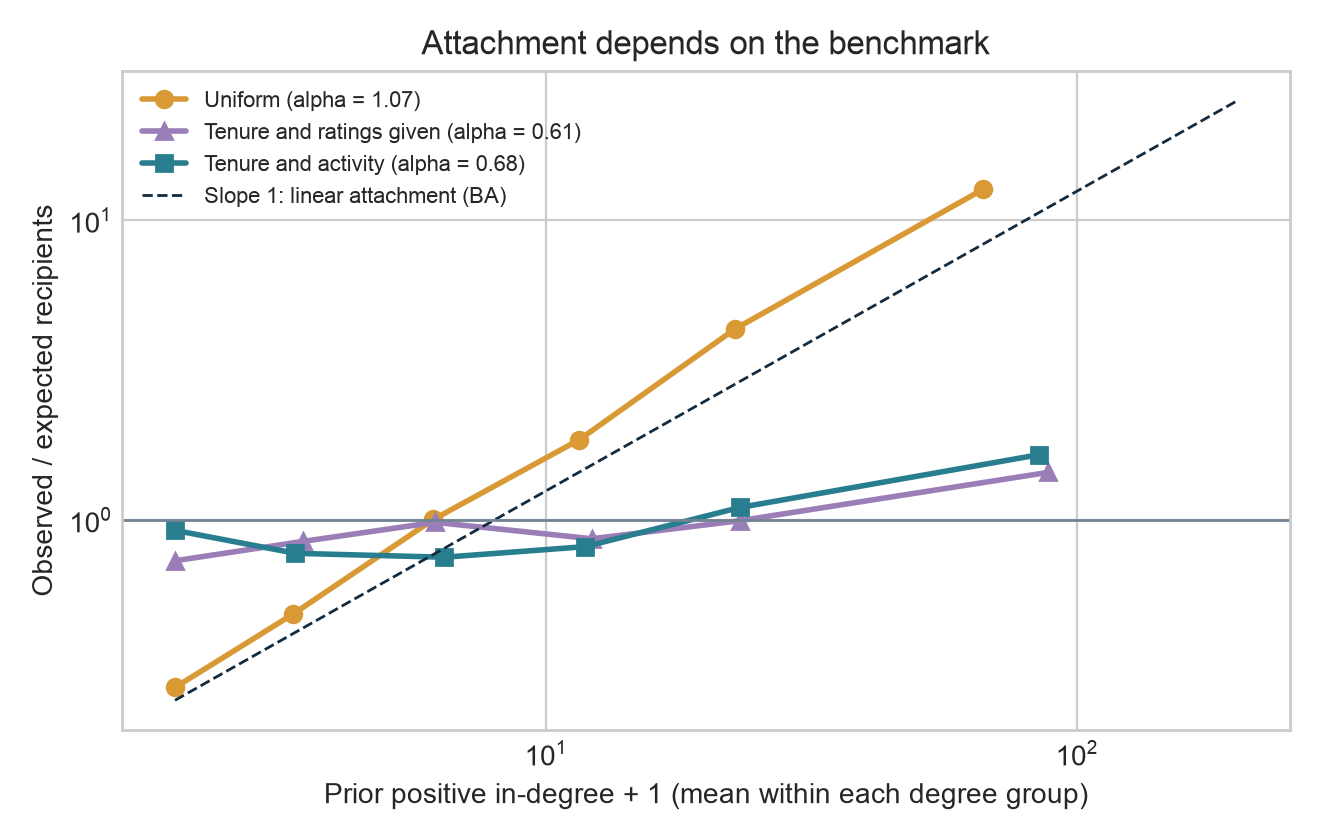

In [9]:
columns = ['benchmark', 'events', 'attachment_exponent_alpha', 'alpha_standard_error', 'ratio_0', 'ratio_2-3', 'ratio_32+']
display(benchmarks[columns].round(3))
Image(filename=str(THEORY / 'attachment_kernel.png'))

- Compared with all possible recipients, $\alpha = 1.07$: close to linear, so at first it looks like BA.
- Matching on **tenure only** makes the 32+ ratio bigger (18.46). Matching on **recent activity only** brings it down to 1.71, almost the same as matching on both (1.65, with $\alpha = 0.68$, sublinear). Most of the drop comes with matching on recent activity, not account age. This is an association, not proof that activity causes it.
- Activity includes ratings received, which overlaps with degree. Counting only ratings a user **gave** still gives 1.44, so that overlap is not the reason.
- Some advantage remains in every comparison; the data cannot tell us why.

In [10]:
display(returns.round(3))
display(pd.Series(meta['return_ratings']).round(4))
print('Median minutes before a rating is returned:', round(meta['return_ratings']['median_days_to_return'] * 24 * 60, 1))

,prior_positive_in_degree,eligible_events,events_returning_an_earlier_rating,share_returning
0,0,601,477,0.794
1,1,3090,1145,0.371
2,2-3,3717,1578,0.425
3,4-7,4145,1903,0.459
4,8-15,4223,2142,0.507
5,16-31,4001,2049,0.512
6,32+,7356,4144,0.563


eligible_events                       27133.0000
events_returning_an_earlier_rating    13438.0000
share_returning                           0.4953
median_days_to_return                     0.0026
share_returned_within_7_days              0.8730
dtype: float64

Median minutes before a rating is returned: 3.7


About half (49.5%) of the ratings to users already in the network return an earlier rating, usually within minutes (median 3.7). They look like "you rated me, so I rate you" after a trade, not independent choices. This is why users with no earlier ratings looked popular in notebook 04: counting only the first rating in each pair brings that ratio close to 1. The 32+ result hardly changes.

## 6. Did yearly concentration really fall?

Notebook 03 showed the share of each year's new ratings going to the top 1% falling after 2013. Here every year is redrawn to the same 743 ratings.

In [11]:
equal_volume.round(4)

,year,ratings,top_1_percent_share,equal_volume_ratings,equal_volume_share_mean,equal_volume_share_low,equal_volume_share_high,fixed_recipients,fixed_recipients_share,fixed_recipients_equal_volume_mean,fixed_recipients_equal_volume_low,fixed_recipients_equal_volume_high
0,2011,7603,0.1527,743,0.0954,0.0794,0.1117,4,0.0583,0.0642,0.0498,0.0781
1,2012,8622,0.1967,743,0.1121,0.0929,0.1332,4,0.0699,0.0748,0.0592,0.0915
2,2013,11138,0.2096,743,0.1205,0.1009,0.1413,4,0.0729,0.0778,0.0619,0.0956
3,2014,3555,0.1437,743,0.0961,0.0794,0.1157,4,0.0731,0.0786,0.0646,0.0942
4,2015,929,0.1130,743,0.0996,0.0834,0.1225,4,0.1130,0.1156,0.1063,0.1252


At equal volume 2013 and 2015 overlap, and a fixed number of recipients gets a larger share. **Most of the fall comes from fewer ratings, not from less concentration.**

## 7. Robustness: the critical threshold

From the course (Chapter 8): a giant component exists while $\kappa = \langle k^2\rangle / \langle k\rangle > 2$ (the Molloy–Reed criterion). In a large random network with the same degrees, removing a random fraction $f$ of the nodes destroys it at the **critical threshold**

$$f_c = 1 - \frac{1}{\kappa - 1}.$$

For ER, $\kappa = \langle k\rangle + 1$, so $f_c = 1 - 1/\langle k\rangle$.

ER:   f_c = 1 - 1/<k> = 0.842
Real: kappa = 71.9   f_c = 0.986


,network,heterogeneity_kappa,molloy_reed_threshold,random_removal_collapse_fraction,targeted_removal_collapse_fraction
0,Observed,71.912,0.986,0.93,0.150
1,Rewired,71.912,0.986,0.94,0.150
2,BA,16.053,0.934,0.90,0.300
3,ER,7.330,0.842,0.85,0.625


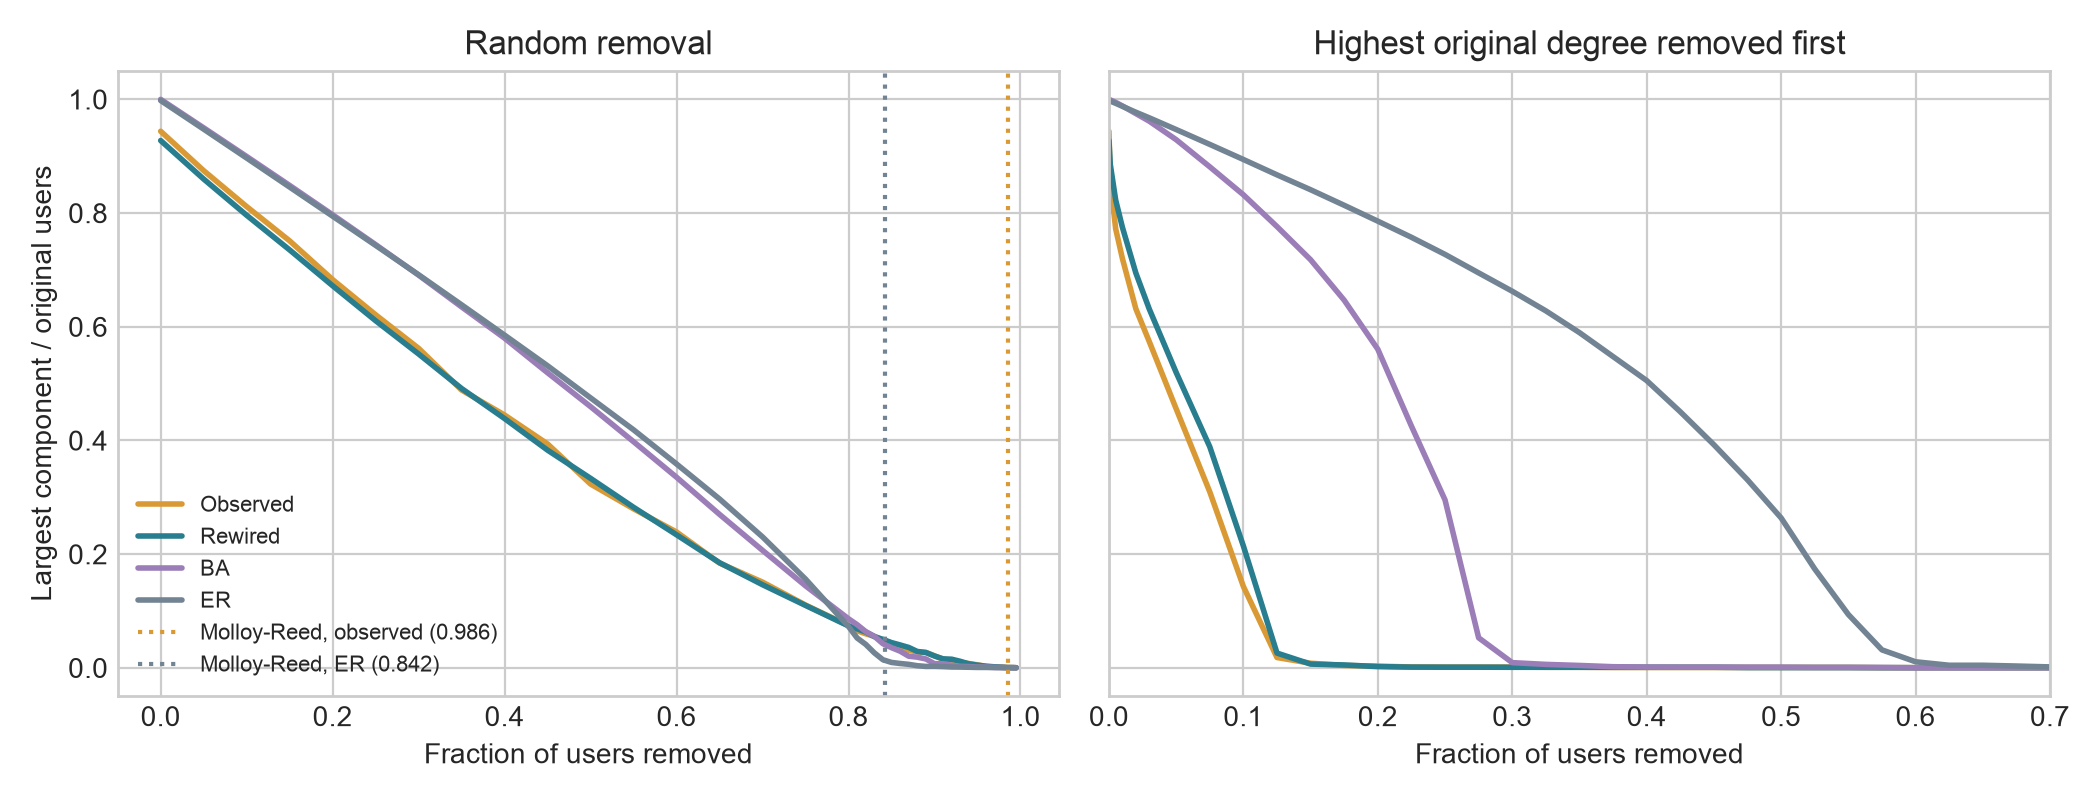

In [12]:
def critical_threshold(kappa):
    return 1 - 1 / (kappa - 1)

kappa = thresholds.set_index('network').loc['Observed', 'heterogeneity_kappa']
print('ER:   f_c = 1 - 1/<k> =', round(1 - 1 / k_mean, 3))
print('Real: kappa =', round(kappa, 1), '  f_c =', round(critical_threshold(kappa), 3))
display(thresholds.round(3))
Image(filename=str(THEORY / 'percolation_vs_theory.png'))

**Random failures** barely hurt the real network: its largest component only drops below 1% of users after about 93% are removed. The formula gives $f_c = 0.986$, but that is a benchmark for an infinite random network with the same degrees; our 93% comes from this finite, clustered network with a 1% cutoff, so the two are related but not the same quantity. A **targeted attack** on the hubs breaks it after removing only 15%, as the course predicts for networks with hubs. The rewired networks break at the same point, so this comes from the degrees. This is a "what if" experiment, not something that happened on the platform.

## 8. How stable are the communities?

Louvain gives slightly different results with different random seeds, so the script ran it with 20 seeds. Each result is compared with the reported one using normalized mutual information (NMI; 1 means the same partition).

In [13]:
display(stability.round(3))
stability[['modularity', 'largest_group_users', 'nmi_with_reported_partition']].agg(['min', 'mean', 'max']).round(3)

,seed,modularity,groups_with_two_or_more_users,largest_group_users,nmi_with_reported_partition,mean_best_jaccard_for_five_largest_groups
0,2026,0.504,33,1096,1.000,1.000
1,2027,0.497,36,1395,0.642,0.572
2,2028,0.508,31,1139,0.816,0.836
3,2029,0.490,39,1173,0.634,0.577
4,2030,0.506,36,1024,0.699,0.704
5,2031,0.494,38,1294,0.613,0.539
6,2032,0.500,32,1174,0.627,0.622
7,2033,0.500,35,1040,0.690,0.660
8,2034,0.504,36,1325,0.616,0.576
9,2035,0.505,35,1258,0.650,0.634


,modularity,largest_group_users,nmi_with_reported_partition
min,0.487,1024.00,0.606
mean,0.502,1228.45,0.673
max,0.517,1457.00,1.000


Modularity stays between 0.487 and 0.517, always well above the ER, BA and rewired values (0.33–0.39), so the network clearly has community structure. But the largest group has between 1,024 and 1,457 users depending on the seed, and the mean NMI is only about 0.66, so **which users end up in which group is not stable**. We should not give "Group 1" a social meaning.

## 9. What this means

**For the platform**

- Reputation is concentrated and stays concentrated. Old ratings stay in this data while new ratings fell sharply after 2013, so a high score may describe past standing more than current standing.
- The trust record depends on a few accounts: losing a small number of hubs disconnects far more of it than losing the same number of random users.
- A rating count is not a count of independent opinions, because about half the ratings are quick returns.
- Being recently active seems to matter more for getting rated than an old reputation, but we cannot separate this from how much a user trades.

**Limits.** Ratings are opinions, not checked trades or fraud reports. The data has no registration dates, trade volumes or rating changes, and one person may use several IDs. Our tenure and activity groups are rough, and the formulas are for very large networks.

**Further work.** A choice model that combines degree, recent activity and returned ratings; the fitness and aging models from Week 6; null models that respect time order; signed triads using the negative ratings; attacks that recompute degree after each removal; consensus clustering; and comparing network position with known fraud cases.